# Task 03 — Complaint triage with text classification, and what happens when the regulator changes the categories

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Consumer Complaint Database](https://www.kaggle.com/datasets/selener/consumer-complaint-database) — the US Consumer Financial Protection Bureau's public complaint register (Kaggle mirror, May 2019)
**Task family:** NLP / text classification, label-schema drift · **Companions:** `01_aml_graph_triage.ipynb` (graphs), `02_card_fraud_tabular.ipynb` (tabular), `04_erp_document_rag.ipynb` (document retrieval)

---

## The task card

> **Board question.** *Our complaints team routes roughly two thousand cases a month by hand and misses the regulator's response deadline on some of them. Can a model route each complaint to the right product team on arrival — and keep working when the regulator rewrites the category list?*

**Business context.** A bank or payment institution under MFSA supervision (or the Arbiter for Financial Services, for consumer complaints) must acknowledge and answer complaints within fixed windows. Routing is the first step: a mortgage complaint that lands with the cards team loses days. Routing is a **classification of free text into a taxonomy the regulator owns**, and regulators change taxonomies. The CFPB did exactly that on 24 April 2017: it merged, split and renamed its product categories. A model trained on the old list is not "a bit worse" the next morning; it is answering a question nobody asks any more.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **routing model** over complaint narratives, packaged and reproducible, evaluated forward in time across the taxonomy change;
2. a **versioned crosswalk** from the old taxonomy to the new one — the semantic-layer fix to an ML problem — with tests;
3. the **operational wrapper** the unit teaches: package, tests, CI gate on macro-F1, registered model, model card, monitoring plan that watches the *label space*, not only the inputs;
4. a one-page **stakeholder recommendation** covering value, the human-review policy and the data-protection position.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Online classification at intake; where routing sits between the complaints portal and the case-management tool; the regulatory response window as a business constraint |
| 2 · MLOps | Temporal validation across a schema change; quality gate on macro-F1; a contract check on the output label space next to the usual drift statistics; retraining trigger on a taxonomy release |
| 3 · Semantic layer | The product/issue taxonomy as an ontology; the old→new crosswalk as a versioned, validated artefact (Session 08); one-to-many mappings that need the sub-product |
| 4 · LLM/RAG | Drafting a first response grounded on similar resolved complaints (Session 10); judge-based evaluation of generated replies (Session 11) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook leaves two traps in, flagged ⚠; turning each into a test is part of the task.

**Honesty note.** Unlike tasks 01, 02 and 04, this data is **real**: narratives written by US consumers who consented to publication, with personal details masked as `XXXX`. Treat it with the care you would give a Maltese complaints file: no attempt to re-identify, no quoting of narratives outside the classroom, and a GDPR position in your write-up even though the data is American.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at the taxonomy change | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The crosswalk, the TF-IDF and linear SVM router, the day the labels changed, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | Monitoring the label space after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the failure your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_narratives` (Section 1); `crosswalk` with `OLD_TO_NEW` (Section 3); the TF-IDF vectoriser and `LinearSVC` training (Section 4) and the retrain on crosswalked labels (Section 5); `predicted_label_mix` and `psi` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** train 132,581 complaints, validation 31,495 (old taxonomy) and test 202,156 (new taxonomy); 300,000 TF-IDF features; validation accuracy 0.858 and macro-F1 0.650; on the test period, accuracy 0.306 for the untouched model (60.2 % of answers in a label that no longer exists), 0.764 with crosswalked predictions and 0.793 (macro-F1 0.726) retrained on crosswalked labels.
- **Runtime:** about 4 minutes on a laptop (250 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
import os, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pc
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 80)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "selener/consumer-complaint-database"
TAXONOMY_CHANGE = pd.Timestamp("2017-04-24")       # CFPB's new product/sub-product/issue list went live
TRAIN_START, TRAIN_END = pd.Timestamp("2015-03-01"), pd.Timestamp("2017-01-01")   # narratives exist from Mar 2015
VALID_END = TAXONOMY_CHANGE                         # validation: Jan 2017 → the change (old taxonomy)
TEST_END = pd.Timestamp("2019-01-01")              # test: the change → Dec 2018 (new taxonomy)
MAX_FEATURES = 300_000                             # TF-IDF vocabulary cap; lower it on a small laptop
RESPONSE_WINDOW_DAYS = 15                          # the regulator's expectation for a substantive reply

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
import sklearn; print(f"pandas {pd.__version__} · scikit-learn {sklearn.__version__}")

pandas 3.0.5 · scikit-learn 1.9.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_narratives`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `selener/consumer-complaint-database`, a May-2019 snapshot of the CFPB Consumer Complaint Database (`rows.csv`, 737 MB). The live database is at consumerfinance.gov |
| **Licence** | US Government Works (public domain in the US); the Kaggle listing carries no further restriction |
| **Provenance** | **Real.** Complaints submitted to the CFPB Dec 2011 – May 2019. Narratives are published only where the consumer opted in (from March 2015) and after the CFPB masked personal details as `XXXX` |
| **Size** | 1.28 M complaints; 383,564 with a narrative (30 %); 167 distinct issues; 18 product labels across two taxonomies |
| **Schema** | `Date received`, `Product`, `Sub-product`, `Issue`, `Sub-issue`, `Consumer complaint narrative`, `Company public response`, `Company`, `State`, `ZIP code`, `Tags`, `Consumer consent provided?`, `Submitted via`, `Date sent to company`, `Company response to consumer`, `Timely response?`, `Consumer disputed?`, `Complaint ID` |
| **Label** | `Product` — chosen by the consumer from the CFPB's list at submission time, i.e. the routing category |
| **Window used here** | Narratives only. Train Mar 2015 – Dec 2016 (132,581); validate Jan 2017 – 23 Apr 2017 (31,495; old taxonomy); test 24 Apr 2017 – Dec 2018 (202,156; new taxonomy) |
| **PII** | Masked by the CFPB; `ZIP code` is truncated to 3 digits for narrative complaints; `Company` is a real institution name |

**Known quirks you must handle (and should mention in your model card):**

1. **The taxonomy changed on 24 April 2017.** Nine old product labels disappear (`Bank account or service`, `Consumer Loan`, `Credit card`, `Credit reporting`, `Money transfers`, `Other financial service`, `Payday loan`, `Prepaid card`, `Virtual currency`), six new ones appear (`Checking or savings account`, `Credit card or prepaid card`, `Credit reporting, credit repair services, or other personal consumer reports`, `Money transfer, virtual currency, or money service`, `Payday loan, title loan, or personal loan`, `Vehicle loan or lease`), three survive (`Debt collection`, `Mortgage`, `Student loan`). The `Issue` and `Sub-issue` lists changed at the same time. This notebook is built around it.
2. **The consumer picks the label.** `Product` is self-reported at submission, not assigned by an expert. Label noise is real: a credit-card dispute about a debt collector may be filed under either.
3. ⚠ **`Issue` is downstream of `Product`.** The submission form shows the issue list *for the product already chosen*, so `Issue` is not a feature available at routing time — it is a leak, and its vocabulary changed in 2017 too.
4. **Narratives only exist with consent**, so the 30 % with text are not a random sample of all complaints (web submissions, certain products and more engaged consumers are over-represented).
5. **US-centric** institutions and products; the method transfers, the vocabulary does not. Expect to retrain on local data.
6. `Consumer disputed?` is blank after mid-2017 (the CFPB stopped collecting it), so it cannot serve as a target past that date.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_narratives() -> pd.DataFrame:
    '''Complaints that carry a narrative, with tidy column names; cached as parquet.'''
    cache = PROCESSED / "cfpb_narratives.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    src = get_raw("rows.csv") if (RAW / "rows.csv").exists() or not (RAW / "cfpb_rows.csv").exists() else RAW / "cfpb_rows.csv"
    tbl = pc.read_csv(src, read_options=pc.ReadOptions(block_size=1 << 24),
                      parse_options=pc.ParseOptions(newlines_in_values=True),
                      convert_options=pc.ConvertOptions(strings_can_be_null=True))
    df = tbl.to_pandas()
    df.columns = [c.strip() for c in df.columns]
    df = df.rename(columns={"Date received": "date", "Product": "product", "Sub-product": "sub_product", "Issue": "issue",
                            "Sub-issue": "sub_issue", "Consumer complaint narrative": "text", "Company": "company",
                            "State": "state", "Submitted via": "channel", "Company response to consumer": "response",
                            "Timely response?": "timely", "Consumer disputed?": "disputed", "Complaint ID": "complaint_id",
                            "Tags": "tags"})
    df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
    df = df[df.text.notna()][["complaint_id", "date", "product", "sub_product", "issue", "sub_issue", "text", "company",
                               "state", "channel", "response", "timely", "disputed", "tags"]].reset_index(drop=True)
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return df

cx = load_narratives()
cx["taxonomy"] = np.where(cx.date < TAXONOMY_CHANGE, "old (to 23 Apr 2017)", "new (from 24 Apr 2017)")
print(f"{len(cx):,} complaints with a narrative · {cx.date.min():%Y-%m-%d} → {cx.date.max():%Y-%m-%d} · "
      f"{cx['product'].nunique()} product labels across both taxonomies · {cx.memory_usage(deep=True).sum()/1e6:.0f} MB")
cx.head(3)[["date", "product", "sub_product", "issue", "company", "text"]]

383,564 complaints with a narrative · 2015-03-19 → 2019-03-23 · 18 product labels across both taxonomies · 534 MB


,date,product,sub_product,issue,company,text
0,2019-03-23,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",The Summer of XX/XX/2018 I was denied a mortgage loan due to a charge off fr...
1,2019-03-22,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",There are many mistakes appear in my report without my understanding.
2,2019-03-22,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",There are many mistakes appear in my report without my understanding.


## 2 · First look: the volume, the consent, and the day the labels changed

*Part A · Explore · read; the 24 April 2017 label change it shows is what your monitoring must catch.*

labels only before the change (9): ['Bank account or service', 'Consumer Loan', 'Credit card', 'Credit reporting', 'Money transfers', 'Other financial service', 'Payday loan', 'Prepaid card', 'Virtual currency']
labels only after the change (6): ['Checking or savings account', 'Credit card or prepaid card', 'Credit reporting, credit repair services, or other personal consumer reports', 'Money transfer, virtual currency, or money service', 'Payday loan, title loan, or personal loan', 'Vehicle loan or lease']
labels on both sides (3): ['Debt collection', 'Mortgage', 'Student loan']


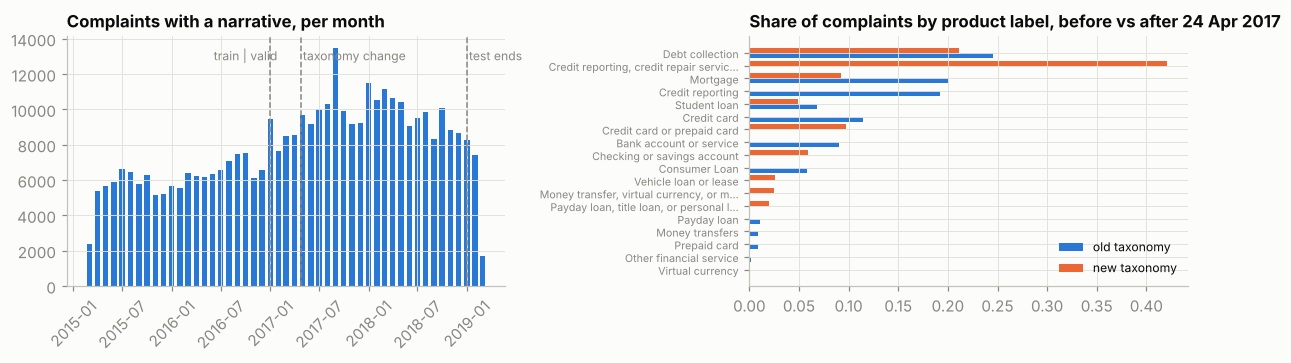

In [3]:
monthly = cx.groupby(cx.date.dt.to_period("M")).size()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.bar(monthly.index.to_timestamp(), monthly.values, width=20, color=SERIES[0])
for x, lab, dx in [(TRAIN_END, "train | valid", -210), (TAXONOMY_CHANGE, "taxonomy change", 8), (TEST_END, "test ends", 8)]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
    ax.text(x + pd.Timedelta(days=dx), monthly.max() * 0.95, lab, color=MUTED, fontsize=8)
ax.set_title("Complaints with a narrative, per month"); ax.tick_params(axis="x", rotation=45)

ax = axes[1]
old = cx[cx.taxonomy.str.startswith("old")]["product"].value_counts(normalize=True)
new = cx[cx.taxonomy.str.startswith("new")]["product"].value_counts(normalize=True)
labels = sorted(set(old.index) | set(new.index), key=lambda l: -(old.get(l, 0) + new.get(l, 0)))
y = np.arange(len(labels))
ax.barh(y + 0.2, [old.get(l, 0) for l in labels], height=0.4, color=SERIES[0], label="old taxonomy")
ax.barh(y - 0.2, [new.get(l, 0) for l in labels], height=0.4, color=SERIES[1], label="new taxonomy")
ax.set_yticks(y); ax.set_yticklabels([l[:38] + ("…" if len(l) > 38 else "") for l in labels], fontsize=7)
ax.invert_yaxis(); ax.set_title("Share of complaints by product label, before vs after 24 Apr 2017"); ax.legend(fontsize=8)
plt.tight_layout()

old_only = sorted(set(old.index) - set(new.index)); new_only = sorted(set(new.index) - set(old.index)); both = sorted(set(old.index) & set(new.index))
print(f"labels only before the change ({len(old_only)}): {old_only}")
print(f"labels only after the change ({len(new_only)}): {new_only}")
print(f"labels on both sides ({len(both)}): {both}")

Nine labels vanish, six appear, three survive. Nothing in the text changed that day; the *answer key* did. Keep that picture in mind for Section 5.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The crosswalk: a semantic-layer artefact, not a modelling trick

*Part B · Given model · package `crosswalk` as a versioned artefact; C1 tests it and fixes Trap 2.*

The CFPB published what merged into what. Written down as a table it is a **crosswalk** between two versions of an ontology, and it has the two properties that make Session 08's point: most of it is one-to-one, but `Consumer Loan` splits into two new categories and the split needs the **sub-product** to resolve. A crosswalk is code: it is versioned, it has tests, and it runs in CI.

In [4]:
OLD_TO_NEW = {
    "Bank account or service": "Checking or savings account",
    "Credit card": "Credit card or prepaid card",
    "Prepaid card": "Credit card or prepaid card",
    "Credit reporting": "Credit reporting, credit repair services, or other personal consumer reports",
    "Money transfers": "Money transfer, virtual currency, or money service",
    "Virtual currency": "Money transfer, virtual currency, or money service",
    "Other financial service": "Money transfer, virtual currency, or money service",   # approximate: see task C2
    "Payday loan": "Payday loan, title loan, or personal loan",
}

def crosswalk(product: str, sub_product) -> str:
    '''Map an old-taxonomy product label to the new taxonomy. Labels already in the new taxonomy pass through.'''
    if product == "Consumer Loan":                               # one-to-many: needs the sub-product
        return "Vehicle loan or lease" if str(sub_product).startswith("Vehicle") else "Payday loan, title loan, or personal loan"
    return OLD_TO_NEW.get(product, product)

# tests a CI job would run on the crosswalk (Session 05): every old label maps to a label that exists in the new taxonomy
NEW_LABELS = set(new.index)
assert all(crosswalk(p, "") in NEW_LABELS for p in old.index), "crosswalk maps to a label outside the new taxonomy"
assert crosswalk("Consumer Loan", "Vehicle loan") == "Vehicle loan or lease"
assert crosswalk("Consumer Loan", "Installment loan") == "Payday loan, title loan, or personal loan"
assert crosswalk("Mortgage", None) == "Mortgage"

cx["product_new"] = [crosswalk(p, s) for p, s in zip(cx["product"], cx["sub_product"])]
print(f"{cx['product'].nunique()} raw labels → {cx['product_new'].nunique()} after the crosswalk; "
      f"new-taxonomy labels: {sorted(NEW_LABELS) == sorted(cx.product_new.unique())}")
pd.crosstab(cx.loc[cx.taxonomy.str.startswith('old'), 'product'], cx.loc[cx.taxonomy.str.startswith('old'), 'product_new']).pipe(
    lambda t: t.loc[:, t.sum() > 0]).style.format("{:,}").background_gradient(cmap="Blues", axis=None)

18 raw labels → 9 after the crosswalk; new-taxonomy labels: True


product_new,Checking or savings account,Credit card or prepaid card,"Credit reporting, credit repair services, or other personal consumer reports",Debt collection,"Money transfer, virtual currency, or money service",Mortgage,"Payday loan, title loan, or personal loan",Student loan,Vehicle loan or lease
product,,,,,,,,,
Bank account or service,"14,885",0,0,0,0,0,0,0,0
Consumer Loan,0,0,0,0,0,0,"3,371",0,"6,103"
Credit card,0,"18,838",0,0,0,0,0,0,0
Credit reporting,0,0,"31,588",0,0,0,0,0,0
Debt collection,0,0,0,"40,343",0,0,0,0,0
Money transfers,0,0,0,0,"1,497",0,0,0,0
Mortgage,0,0,0,0,0,"32,797",0,0,0
Other financial service,0,0,0,0,292,0,0,0,0
Payday loan,0,0,0,0,0,0,"1,747",0,0


## 4 · Baseline: TF-IDF and a linear classifier, trained before the change

*Part B · Given model · package the TF-IDF and linear SVM training unchanged and reproduce its numbers (C2).*

The baseline is deliberately classical. TF-IDF over unigrams and bigrams plus a linear SVM trains in under a minute on a laptop, is fully explainable (the weights are words), and is what most production complaint-routing systems still run. It is the model you are given: you package, evaluate and monitor it, and you do not replace it with embeddings or a transformer.

Training uses the **old labels exactly as the data had them in 2016**, because that is what a team would have done in 2016.

In [5]:
tr = (cx.date >= TRAIN_START) & (cx.date < TRAIN_END)
va = (cx.date >= TRAIN_END) & (cx.date < VALID_END)
te = (cx.date >= TAXONOMY_CHANGE) & (cx.date < TEST_END)
print(f"train {tr.sum():,} · valid {va.sum():,} (old taxonomy) · test {te.sum():,} (new taxonomy)")

t0 = time.time()
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=MAX_FEATURES, sublinear_tf=True, dtype=np.float32)
X_tr = vec.fit_transform(cx.loc[tr, "text"])
X_va, X_te = vec.transform(cx.loc[va, "text"]), vec.transform(cx.loc[te, "text"])
print(f"TF-IDF: {X_tr.shape[1]:,} features · {time.time()-t0:.0f}s")

t0 = time.time()
clf_old = LinearSVC(C=0.5).fit(X_tr, cx.loc[tr, "product"])
p_va = clf_old.predict(X_va)
print(f"validation (Jan–Apr 2017, old labels): accuracy {accuracy_score(cx.loc[va, 'product'], p_va):.3f} · "
      f"macro-F1 {f1_score(cx.loc[va, 'product'], p_va, average='macro'):.3f} · fit {time.time()-t0:.0f}s")

train 132,581 · valid 31,495 (old taxonomy) · test 202,156 (new taxonomy)


TF-IDF: 300,000 features · 133s


validation (Jan–Apr 2017, old labels): accuracy 0.858 · macro-F1 0.650 · fit 36s


In [6]:
# What the model learned: the strongest words per class (the explanation an analyst or a regulator would ask for)
vocab = np.array(vec.get_feature_names_out())
top = {cls: ", ".join(vocab[np.argsort(-w)[:8]]) for cls, w in zip(clf_old.classes_, clf_old.coef_)}
pd.Series(top, name="top positive terms").to_frame().style.set_properties(**{"text-align": "left"})

,top positive terms
Bank account or service,"bank, scottrade, overdraft, debit card, branch, deposit, checking, debit"
Consumer Loan,"vehicle, car, loan, ally, finance, santander, honda, toyota"
Credit card,"card, discover, macy, capital one, citi, barclay, chase, target"
Credit reporting,"equifax, experian, transunion, trans union, trans, report, inquiries, xxxx bank"
Debt collection,"debt, collection, recovery, afni, midland, collections, owe, inc"
Money transfers,"moneygram, paypal, western union, transfer, western, money, money transfer, money gram"
Mortgage,"mortgage, ocwen, modification, escrow, ditech, nationstar, seterus, foreclosure"
Other financial service,"money order, lexington law, lexington, global client, client solutions, check cashing, to cash, global"
Payday loan,"payday, loan, cash, lender, borrowed, payday loans, pay day, cashnet"
Prepaid card,"rushcard, prepaid, serve, netspend, card, prepaid card, gift, rush card"


An 86 % routing accuracy on the validation months, with recognisable vocabulary per class. A team in April 2017 would have shipped this.

## 5 · Monday 24 April 2017: the same model, the new answer key

*Part B · Given model · reproduce the three strategies' test numbers (C2); E1 shadows the retrained model.*

Score the test period with the model exactly as deployed. Then apply the two fixes a team has available: translate the model's *predictions* through the crosswalk (no retraining, minutes), or translate the *training labels* and retrain (hours, better).

In [7]:
y_te = cx.loc[te, "product"].values                    # the truth, in the new taxonomy
p_te_raw = clf_old.predict(X_te)                       # the deployed model's answers, in the old taxonomy
p_te_mapped = np.array([OLD_TO_NEW.get(p, p) for p in p_te_raw])   # fix 1: crosswalk the predictions (Consumer Loan cannot be resolved: no sub-product in a prediction)

t0 = time.time()
clf_new = LinearSVC(C=0.5).fit(X_tr, cx.loc[tr, "product_new"])     # fix 2: crosswalk the training labels, retrain
p_te_retrained = clf_new.predict(X_te)
print(f"retrain on crosswalked labels: {time.time()-t0:.0f}s")

results = pd.DataFrame([
    {"strategy": "deployed model, untouched", "accuracy": accuracy_score(y_te, p_te_raw), "macro-F1": f1_score(y_te, p_te_raw, average="macro"),
     "answers in a label that no longer exists": np.mean(~np.isin(p_te_raw, list(NEW_LABELS)))},
    {"strategy": "fix 1 · crosswalk the predictions", "accuracy": accuracy_score(y_te, p_te_mapped), "macro-F1": f1_score(y_te, p_te_mapped, average="macro"),
     "answers in a label that no longer exists": np.mean(~np.isin(p_te_mapped, list(NEW_LABELS)))},
    {"strategy": "fix 2 · crosswalk the labels, retrain", "accuracy": accuracy_score(y_te, p_te_retrained), "macro-F1": f1_score(y_te, p_te_retrained, average="macro"),
     "answers in a label that no longer exists": 0.0},
]).set_index("strategy")
results.style.format({"accuracy": "{:.3f}", "macro-F1": "{:.3f}", "answers in a label that no longer exists": "{:.1%}"})

retrain on crosswalked labels: 33s


,accuracy,macro-F1,answers in a label that no longer exists
strategy,,,
"deployed model, untouched",0.306,0.137,60.2%
fix 1 · crosswalk the predictions,0.764,0.557,5.2%
"fix 2 · crosswalk the labels, retrain",0.793,0.726,0.0%


,precision,recall,f1-score,support
"Credit reporting, credit repair services, or other personal consumer reports",0.92,0.74,0.82,"85,148"
Debt collection,0.76,0.83,0.80,"42,714"
Credit card or prepaid card,0.69,0.84,0.76,"19,645"
Mortgage,0.78,0.96,0.86,"18,674"
Checking or savings account,0.66,0.90,0.76,"11,740"
Student loan,0.75,0.87,0.81,"9,768"
Vehicle loan or lease,0.53,0.76,0.62,"5,315"
"Money transfer, virtual currency, or money service",0.93,0.38,0.54,"5,111"
"Payday loan, title loan, or personal loan",0.65,0.49,0.56,"4,041"


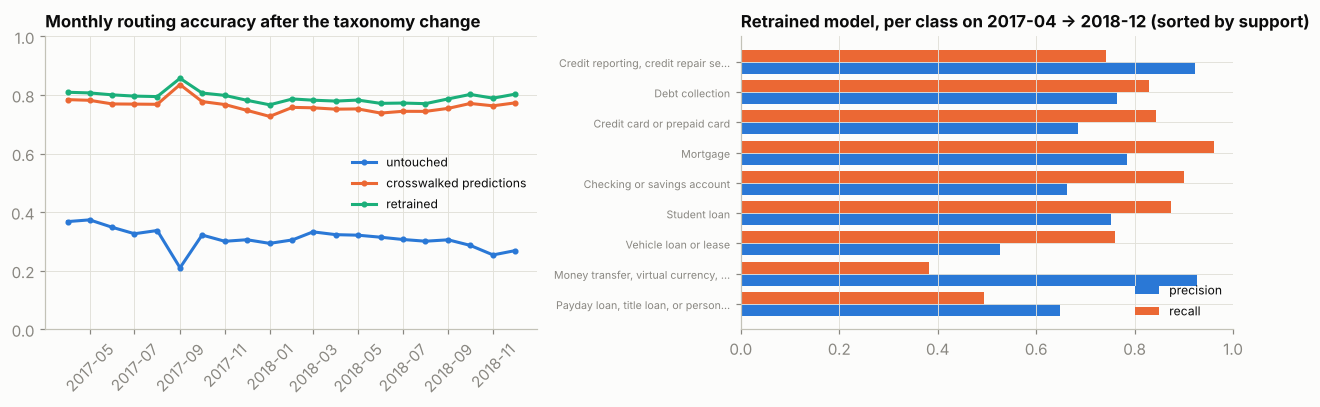

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axes[0]
months = cx.loc[te, "date"].dt.to_period("M").values
acc = pd.DataFrame({"m": months, "untouched": p_te_raw == y_te, "crosswalked predictions": p_te_mapped == y_te,
                    "retrained": p_te_retrained == y_te}).groupby("m").mean()
for col, color in zip(acc.columns, SERIES):
    ax.plot(acc.index.to_timestamp(), acc[col], "-o", ms=3, lw=2, color=color, label=col)
ax.set_ylim(0, 1); ax.set_title("Monthly routing accuracy after the taxonomy change"); ax.legend(fontsize=8, loc="center right"); ax.tick_params(axis="x", rotation=45)

ax = axes[1]
rep = classification_report(y_te, p_te_retrained, output_dict=True, zero_division=0)
per_class = pd.DataFrame({k: v for k, v in rep.items() if k in NEW_LABELS}).T.sort_values("support", ascending=False)
yy = np.arange(len(per_class))
ax.barh(yy + 0.2, per_class["precision"], height=0.4, color=SERIES[0], label="precision")
ax.barh(yy - 0.2, per_class["recall"], height=0.4, color=SERIES[1], label="recall")
ax.set_yticks(yy); ax.set_yticklabels([l[:34] + ("…" if len(l) > 34 else "") for l in per_class.index], fontsize=7); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_title("Retrained model, per class on 2017-04 → 2018-12 (sorted by support)"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
per_class[["precision", "recall", "f1-score", "support"]].style.format({"precision": "{:.2f}", "recall": "{:.2f}", "f1-score": "{:.2f}", "support": "{:,.0f}"})

**Reading this.** The untouched model drops to about 30 % overnight and gives a non-existent answer for three complaints in five — the case-management tool would reject them, or worse, accept them into a dead queue. Crosswalking the *predictions* recovers most of the loss in minutes and is what you do on the Monday; retraining on crosswalked *labels* is what you do by Friday, and it is better because the model can learn the merged classes directly. Two things the retrained model still cannot do well: the small, heterogeneous `Money transfer…` and `Payday loan…` classes, and the right-hand chart shows why — high precision, low recall: the model only routes there when it is sure. That is a capacity decision for the business (task C3), not a modelling bug.

Note the slow decline through 2018 in the left chart even for the retrained model: ordinary drift on top of the schema shock. A monitoring plan needs both signals.

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

**Trap 1 — the `Issue` column.** On the intake form the consumer chooses a product first and then an issue *from that product's list*. `Issue` therefore encodes the product almost perfectly, and it is not available when routing happens — it is downstream of the decision you are trying to make. Add it as a feature and watch the validation score soar; then watch the same model on the test period, where the issue vocabulary changed with the products.

In [9]:
from scipy.sparse import hstack
from sklearn.preprocessing import OneHotEncoder

oh = OneHotEncoder(handle_unknown="ignore")
I_tr = oh.fit_transform(cx.loc[tr, ["issue"]]); I_va = oh.transform(cx.loc[va, ["issue"]]); I_te = oh.transform(cx.loc[te, ["issue"]])
clf_leak = LinearSVC(C=0.5).fit(hstack([X_tr, I_tr]).tocsr(), cx.loc[tr, "product_new"])
acc_va_leak = accuracy_score(cx.loc[va, "product_new"], clf_leak.predict(hstack([X_va, I_va]).tocsr()))
acc_te_leak = accuracy_score(y_te, clf_leak.predict(hstack([X_te, I_te]).tocsr()))
unseen_issue = 1 - cx.loc[te, "issue"].isin(set(cx.loc[tr, "issue"])).mean()
print(f"text + Issue feature · validation accuracy {acc_va_leak:.3f}  →  test accuracy {acc_te_leak:.3f}")
print(f"share of test complaints whose Issue value never appeared in training: {unseen_issue:.1%}")
print(f"text only (retrained)  · test accuracy {accuracy_score(y_te, p_te_retrained):.3f}")

text + Issue feature · validation accuracy 0.994  →  test accuracy 0.173
share of test complaints whose Issue value never appeared in training: 92.7%


text only (retrained)  · test accuracy 0.793


Near-perfect in validation, catastrophic in test. Both halves are the lesson: a feature that is downstream of the label is a leak however good it looks, and a categorical feature whose vocabulary the regulator owns will change without telling you.

**Trap 2 — `Other financial service`.** The crosswalk above sends it to the money-transfer bucket, which is where *most* of its sub-products (check cashing, money orders, traveller's cheques) went — but its `Credit repair` and `Debt settlement` sub-products went to the credit-reporting bucket. A crosswalk written from the product label alone is wrong for a slice of history. Task C1 asks you to fix it with the sub-product and to write the test that would have caught it.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: monitor the label space, not only the words

*Part C · Productionise · what your monitoring plan must catch (C5); reuse `psi` and `predicted_label_mix`.*

The input drift tools from Session 04 (PSI on text statistics, vocabulary overlap) would have said nothing on 24 April 2017 — people wrote the same complaints. Nor, it turns out, would a PSI on the model's **outputs**: the same text through the same model gives the same predictions, so the predicted-label mix does not move either. What does move, within a day, is the **share of predictions the downstream system rejects** because the label no longer exists — a *contract* check against the live taxonomy, not a statistic. Both are plotted below; the output PSI turns out to be the right tool for a different event in the same stream.

text statistics barely move: mean narrative length 1000 chars before vs 1117 after
output PSI in the first full month after the change (2017-05): 0.13 (below the 0.25 line) · reject rate that month: 53%
output PSI peaks at 0.67 in 2017-09: predicted 'Credit reporting' share 53% vs 18% in the reference months


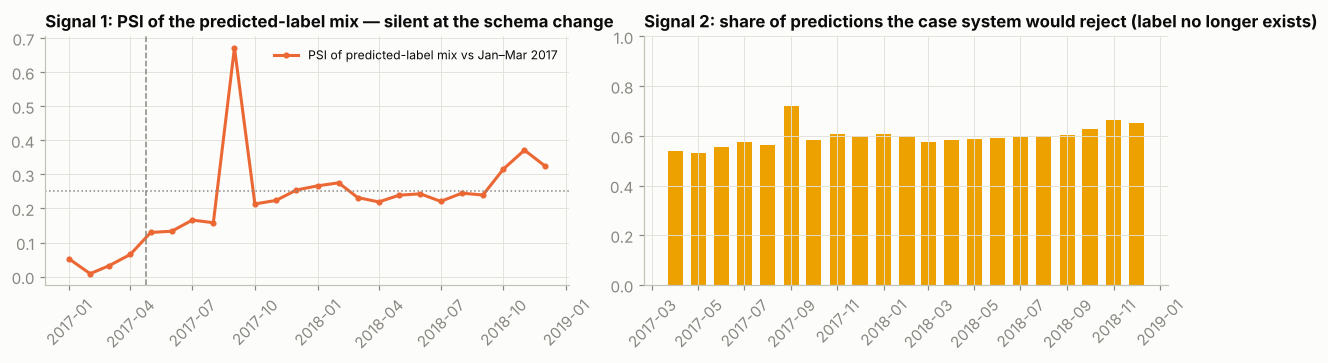

In [10]:
def predicted_label_mix(preds, idx):
    return (pd.DataFrame({"m": cx.loc[idx, "date"].dt.to_period("M").values, "p": preds})
            .groupby("m").p.value_counts(normalize=True).unstack(fill_value=0))

# the deployed model's predictions over validation and test, month by month (April 2017 straddles the change)
months_all = pd.concat([cx.loc[va, "date"], cx.loc[te, "date"]]).dt.to_period("M").values
preds_all = np.concatenate([p_va, p_te_raw])
mix = pd.crosstab(months_all, preds_all, normalize="index")          # predicted-label distribution per month
rejected = pd.Series(~np.isin(p_te_raw, list(NEW_LABELS))).groupby(cx.loc[te, "date"].dt.to_period("M").values).mean()

def psi(ref, cur, eps=1e-6):
    r = np.asarray(ref, dtype=float) + eps; c = np.asarray(cur, dtype=float) + eps
    return float(np.sum((c - r) * np.log(c / r)))
ref = mix.iloc[:3].mean()           # the first three validation months as the reference label mix
psi_m = pd.Series({m: psi(ref.values, mix.loc[m].values) for m in mix.index})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.plot(psi_m.index.to_timestamp(), psi_m.values, "-o", ms=3, lw=2, color=SERIES[1], label="PSI of predicted-label mix vs Jan–Mar 2017")
ax.axvline(TAXONOMY_CHANGE, color=MUTED, ls="--", lw=1); ax.axhline(0.25, color=MUTED, ls=":", lw=1)
ax.set_title("Signal 1: PSI of the predicted-label mix — silent at the schema change"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
ax.bar(rejected.index.to_timestamp(), rejected.values, width=20, color=SERIES[3])
ax.set_ylim(0, 1); ax.set_title("Signal 2: share of predictions the case system would reject (label no longer exists)"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
peak = psi_m.idxmax()
print(f"text statistics barely move: mean narrative length {cx.loc[va, 'text'].str.len().mean():.0f} chars before vs {cx.loc[te, 'text'].str.len().mean():.0f} after")
print(f"output PSI in the first full month after the change (2017-05): {psi_m[pd.Period('2017-05')]:.2f} (below the 0.25 line) · reject rate that month: {rejected[pd.Period('2017-05')]:.0%}")
print(f"output PSI peaks at {psi_m.max():.2f} in {peak}: predicted 'Credit reporting' share {mix.loc[peak, 'Credit reporting']:.0%} vs {ref['Credit reporting']:.0%} in the reference months")

Read the two panels together. **Signal 1 is blind to the schema change**: the output PSI stays under the 0.25 line through the summer of 2017, because nothing the model sees changed. The one month it does fire is September 2017 — the month Equifax disclosed its data breach (7 September 2017) and credit-reporting complaints doubled. That is a genuine input shift, the kind a statistic *should* catch, and it is worth noticing that it happened to a model that was already broken for five months without any statistic saying so. **Signal 2 fires on day one**: three predictions in five land on a label the case system no longer accepts, which is zero before the change by construction. It is not a drift metric; it is a contract test between the model's output space and the live taxonomy, and it is the cheapest alarm in the whole plan.

The lesson for the monitoring plan (task C5): a routing model needs *three* kinds of signal — input statistics for the world changing, output statistics for the model's behaviour changing, and **contract checks** for the label space changing — and a taxonomy release from the regulator is a scheduled retraining trigger, not something to detect after the fact.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles every project covers, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/` package with `get_raw` and `load_narratives` (383,564 narratives, 534 MB), the versioned `crosswalk` with `OLD_TO_NEW` (18 raw labels → 9), the TF-IDF vectoriser (300,000 features) and `LinearSVC`; a routing endpoint the complaints portal calls at intake |
| Monitoring (S04) | Contract check: share of predictions in a label the live taxonomy no longer has (0 % before the change, 53 % in May 2017). Output-mix PSI against the reference months, alarm at 0.25 (0.13 in May 2017; peak 0.67 in Sep 2017, with credit reporting at 53 % of predictions against 18 %). Input statistics: mean narrative length 1,000 → 1,117 characters |
| CI/CD gate (S05) | Macro-F1 on a frozen evaluation month in the new taxonomy: the retrained model scores 0.726 (accuracy 0.793) on the test period; fail below the crosswalked-predictions fix (macro-F1 0.557). Crosswalk completeness and regression tests; a test that fails if `Issue` reaches the features (0.994 in validation, 0.173 in test) |
| MLflow tracking and registry (S06) | Train, validation and test windows, `TAXONOMY_CHANGE`, `MAX_FEATURES`, `SEED`, the crosswalk version and the taxonomy version the model emits; `champion` alias, with the retrained model as challenger in shadow (E1) |
| Offline / online training and serving | Online classification at intake, well inside the 15-day response window (`RESPONSE_WINDOW_DAYS`); offline retraining (133 s for TF-IDF, 33–36 s for the fit) scheduled on a taxonomy release, not detected after it |
| Data and model drift | Label-schema change on 24 April 2017: 9 labels vanish, 6 appear, 3 survive. Accuracy 0.858 on validation → 0.306 on the test period untouched (60.2 % of answers in a dead label), 0.764 with crosswalked predictions, 0.793 retrained. Ordinary drift on top: the slow decline through 2018 and the Equifax surge of Sep 2017 |
| Knowledge base and context (S07–S09) | The product, sub-product and issue taxonomy as an ontology in two versions; the crosswalk as a versioned artefact, with `Consumer Loan` split by sub-product (3,371 to payday and personal loans, 6,103 to vehicle loans) and `Other financial service` needing the sub-product (Trap 2) |
| GenAI and context engineering (S10–S11) | First-draft reply grounded on the three most similar resolved complaints and their public company responses; judge rubric for factuality and tone; a stated list of what is never auto-sent |
| Governance | Real data, US Government Works; narratives published only with consent (30 % of complaints), masked as `XXXX`, ZIP truncated to 3 digits; self-reported label; GDPR position for a Maltese deployment, AI Act human oversight, and the routing audit trail (E2) |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Make the crosswalk a managed artefact, and fix it.** Move `OLD_TO_NEW` and `crosswalk()` into `src/`, give it a version, write the tests shown above plus a completeness test (every label in every year maps into the current taxonomy), and run them in CI (Session 05). Fix `Other financial service` (Trap 2): use the sub-product to route `Credit repair` and `Debt settlement` complaints to the credit-reporting bucket, count how many 2015–2016 complaints change class, and add the regression test that would have caught the original error. Add a test that fails if `Issue` reaches the features (Trap 1). Record the mapping source in an ADR.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the review threshold from reviewer capacity.** The two small classes have low recall. Without a second model, take the SVM's top-class decision score as routing confidence and send complaints below a threshold to a human router; choose the threshold from a reviewer capacity you state, show the accuracy/coverage trade-off, and report how many complaints a day, and which products, go to a person. Write the one-paragraph recommendation to the Head of Complaints and record the threshold in an ADR.
- **C4 — Package, gate, register.** Pipeline in `src/`, tests for the feature pipeline, a CI gate on macro-F1 over a frozen evaluation month, MLflow run tracking, `champion` alias, and a model card that names the consent basis, the masking, the self-reported label, the taxonomy versions and the US-centric vocabulary (Sessions 05–06).
- **C5 — Monitoring plan with a label-space section.** Specify the contract check against the live taxonomy (the downstream-reject alert), the output-mix PSI and what it does and does not catch (use September 2017 as the worked example), the input signals you would still watch, the reference windows and thresholds, and the retraining trigger tied to a taxonomy release (Session 04).

### Extension

- **E1 — Shadow the router on the new taxonomy.** Run the deployed model and the one retrained by C1's crosswalk fix (the same training code, translated labels) side by side on May–Dec 2017 in shadow mode; report agreement and accuracy per month and the switch-over rule you would use.
- **E2 — An audited routing service.** Every routed complaint writes an audit record: complaint ID, time, model version, crosswalk and taxonomy version, the top-3 classes with their scores, and whether it went to a team or to a person. Capture each reviewer override (the team a person moved it to) in the same store, and produce a weekly report of overrides by product and by model version, so that a late reply can be traced to the routing decision behind it.
- **E3 — The deadline.** `Timely response?` is the regulator's own measure. Join routing confidence to timeliness and test whether low-confidence (hard-to-route) complaints are late more often. If so, routing confidence is an SLA risk signal and belongs on the dashboard.
- **E4 — Data protection and the AI Act.** The data is US and public; your deployment is Maltese and private. Write the GDPR position (lawful basis for processing complaint text, retention, the `XXXX` masking as a model for your own pipeline) and the AI Act position (is triage a decision that "significantly affects" the consumer, and what human oversight means for a routing queue).

### Stretch

- **S1 — Draft the first reply.** For a sample of complaints, retrieve the three most similar *resolved* complaints and their public company responses, and generate a grounded first-draft reply (Session 10). Evaluate factuality and tone with a judge rubric (Session 11), and state what must never be auto-sent.
- **S2 — The taxonomy as an ontology.** Model products, sub-products and issues for both taxonomy versions as a small OWL/SKOS vocabulary with `skos:broadMatch`/`skos:exactMatch` links across versions, validate it with SHACL, and generate the crosswalk from it rather than hand-writing it (Session 08).
- **S3 — Local vocabulary.** Build a 200-complaint Maltese golden set (synthetic, written by you, in the MFSA/Arbiter categories) and measure how much of the given US-trained model transfers. Decide in an ADR whether it can go live in Malta as it is, only after re-running the same training code on local labels, or not at all, and what the local labels would cost.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; no narrative text copied into the repository
- [ ] `README.md` states the splits, the taxonomy-change date and how to obtain the data (Kaggle, US Government Works)
- [ ] Crosswalk versioned, tested and run in CI; `Other financial service` fixed
- [ ] Forward-in-time evaluation across the change, reported for all three strategies
- [ ] Human-review threshold chosen from capacity, with the ADR
- [ ] CI gate on macro-F1; registered model with model card; monitoring plan with the label-space section
- [ ] One-page stakeholder recommendation (value, review policy, GDPR and AI Act position)
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `scipy`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`). No GPU needed for the baseline.
- Consumer Financial Protection Bureau, *Consumer Complaint Database* documentation and the April 2017 product/issue taxonomy update notice (consumerfinance.gov).
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 4 (labels and label noise), Ch. 8 (distribution shifts, including label schema change).
- Sculley, D. et al. (2015). *Hidden Technical Debt in Machine Learning Systems* — the "changing external world" and "undeclared consumers" sections apply directly to a regulator-owned taxonomy.

In [11]:
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

notebook finished · total wall time 250s
